# Zero-Shot Ambiguity Detection in Software Requirements Specifications (SRS) using Qwen2.5-3B-Instruct

**Abstract & Overview:**
Requirements ambiguity is a critical precursor to software defects and implementation failures. This experimental notebook assesses the out-of-the-box, zero-shot classification performance of the `Qwen/Qwen2.5-3B-Instruct` Large Language Model (LLM) on the benchmark QuRE dataset (2,109 deduplicated industrial requirements).

The model is evaluated on local GPU infrastructure in half-precision (FP16). To ensure rigorous scientific evaluation, continuous posterior probabilities $P(\text{defect}) \in [0, 1]$ are extracted directly from the next-token logits over the binary target vocabulary (`ok` vs. `defect`), enabling authentic Receiver Operating Characteristic (ROC-AUC) and Precision-Recall (PR-AUC) analysis without reliance on discrete label proxies.

## 1. Environment and Dependencies
Initializes the runtime environment and installs required libraries including PyTorch, HuggingFace Transformers, Accelerate, and Scikit-Learn.

In [1]:
!pip install -q transformers>=4.45.0
!pip install -q accelerate>=0.34.0
!pip install -q datasets
!pip install -q scikit-learn
!pip install -q matplotlib seaborn
!pip install -q pandas numpy

import os, warnings
warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
print('✅ Required libraries installed successfully!')


✅ Required libraries installed successfully!


## 2. Dataset Ingestion and Standardization
Loads the empirical QuRE dataset (2,109 deduplicated requirements). Text preprocessing is standardized via whitespace normalization and a context boundary constraint (800 characters) to ensure strict parity across text and visual modality experiments.

Fetching dataset from repository: https://raw.githubusercontent.com/HoangKhoi1704/VLM-in-ambiguity-RE/main/data/QuRE.csv

[Dataset] Loaded: data/QuRE.csv
   Total samples: 2109
   Columns      : ['id', 'requirement', 'defect', 'weak_word']

Class Distribution:
defect
ok        1486
defect     623
Name: count, dtype: int64


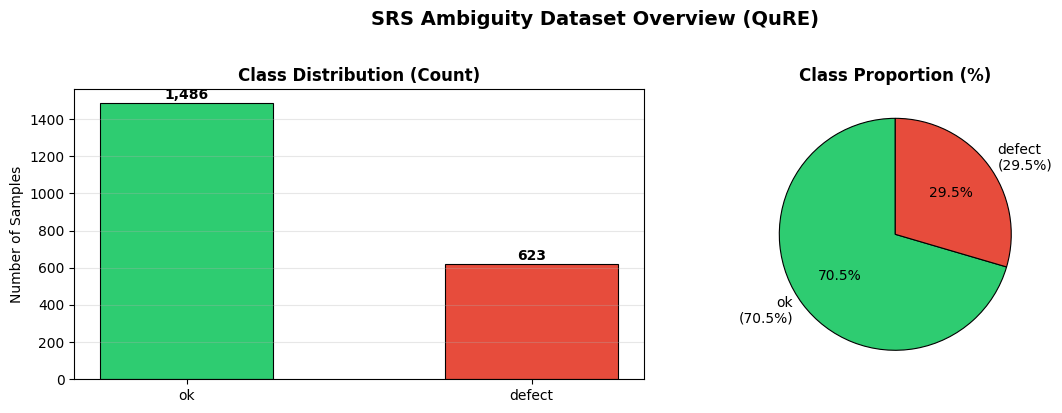

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

candidate_paths = [
    'data/QuRE.csv',
    '../data/QuRE.csv',
    'QuRE.csv',
    'data/datasetRE.csv',
    '../data/datasetRE.csv',
    'datasetRE.csv'
]

filename = None
for candidate in candidate_paths:
    if os.path.exists(candidate):
        filename = candidate
        break

if filename is None:
    try:
        url = 'https://raw.githubusercontent.com/HoangKhoi1704/VLM-in-ambiguity-RE/main/data/QuRE.csv'
        print('Fetching dataset from repository: ' + url)
        df_fetched = pd.read_csv(url)
        os.makedirs('data', exist_ok=True)
        filename = 'data/QuRE.csv'
        df_fetched.to_csv(filename, index=False)
    except Exception:
        pass

if filename is None:
    try:
        from google.colab import files
        print('Upload QuRE.csv or datasetRE.csv:')
        uploaded = files.upload()
        filename = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError('QuRE.csv or datasetRE.csv not found in directory!')

df = pd.read_csv(filename)
print(f'\n[Dataset] Loaded: {filename}')
print(f'   Total samples: {len(df)}')
print(f'   Columns      : {df.columns.tolist()}')
print(f'\nClass Distribution:')
print(df['defect'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

label_order = ['ok', 'defect']
counts = df['defect'].value_counts().reindex(label_order, fill_value=0)
colors = ['#2ecc71', '#e74c3c']

axes[0].bar(label_order, counts, color=colors, width=0.5, edgecolor='black', linewidth=0.8)
axes[0].set_title('Class Distribution (Count)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Samples')
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(counts):
    axes[0].text(i, v + 20, f'{v:,}', ha='center', fontweight='bold')

pcts = [counts['ok'] / len(df) * 100, counts['defect'] / len(df) * 100]
axes[1].pie(
    pcts,
    labels=[f'ok\n({pcts[0]:.1f}%)', f'defect\n({pcts[1]:.1f}%)'],
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.8}
)
axes[1].set_title('Class Proportion (%)', fontsize=12, fontweight='bold')

plt.suptitle('SRS Ambiguity Dataset Overview (QuRE)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 3. Stratified Dataset Partitioning
Applies stratified dataset partitioning (80% Train, 10% Validation, 10% Test) to preserve class balance (~70.2% `ok`, ~29.8% `defect`). Evaluation is performed exclusively on the 10% hold-out test set across configurable random seeds (42, 123, 456).

In [11]:
from sklearn.model_selection import train_test_split

RANDOM_SEED = 123
print(f'Using RANDOM_SEED = {RANDOM_SEED}')

df_trainval, df_test = train_test_split(
    df, test_size=0.10, random_state=RANDOM_SEED, stratify=df['defect']
)

df_train, df_val = train_test_split(
    df_trainval, test_size=0.1111, random_state=RANDOM_SEED, stratify=df_trainval['defect']
)

df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

print('Split summary:')
print(f'   Train : {len(df_train):4d} samples | ok={sum(df_train["defect"]=="ok")} | defect={sum(df_train["defect"]=="defect")}')
print(f'   Val   : {len(df_val):4d} samples | ok={sum(df_val["defect"]=="ok")} | defect={sum(df_val["defect"]=="defect")}')
print(f'   Test  : {len(df_test):4d} samples | ok={sum(df_test["defect"]=="ok")} | defect={sum(df_test["defect"]=="defect")}')
print(f'   Total : {len(df_train)+len(df_val)+len(df_test):4d} samples')


Using RANDOM_SEED = 123
Split summary:
   Train : 1687 samples | ok=1188 | defect=499
   Val   :  211 samples | ok=149 | defect=62
   Test  :  211 samples | ok=149 | defect=62
   Total : 2109 samples


## 4. Prompt Engineering and Chat Template Formulation
Formulates the classification instruction adhering to the Qwen2.5 ChatML format. The model is constrained to binary prediction (`ok` vs. `defect`) given an unannotated requirement input.

In [4]:
import re
from typing import Optional

VALID_LABELS  = {"ok", "defect"}
MAX_REQ_CHARS = 800

SYSTEM_PROMPT = """You are an expert SRS (Software Requirements Specification) analyst.
Your task is to classify whether a given requirement contains a defect (ambiguity, vagueness, or incompleteness).
Respond with ONLY one word: either 'ok' or 'defect'. No explanation."""

def clean_requirement(text: str) -> str:
    """Normalize whitespace and truncate if length exceeds maximum limit."""
    text = re.sub(r'\s+', ' ', text).strip()
    if len(text) > MAX_REQ_CHARS:
        print(f"⚠️  Requirement truncated: {len(text)} → {MAX_REQ_CHARS} characters")
        text = text[:MAX_REQ_CHARS] + "..."
    return text

def build_prompt(requirement: str, label: Optional[str] = None) -> list[dict]:
    """
    Format prompt following Qwen2.5 chat template.

    Args:
        requirement: SRS statement to classify
        label: 'ok' or 'defect' — provided during training only

    Returns:
        list[dict]: messages format cho tokenizer.apply_chat_template()
    """
    if label is not None:
        label = label.strip().lower()
        if label not in VALID_LABELS:
            raise ValueError(f"Invalid label: {label!r}. Accepted: {VALID_LABELS}")

    messages = [
        {"role": "system",  "content": SYSTEM_PROMPT},
        {"role": "user",    "content": f"Requirement: {clean_requirement(requirement)}"},
    ]
    if label is not None:
        messages.append({"role": "assistant", "content": label})

    return messages

def verify_dataset(df, req_col="requirement", label_col="defect") -> None:
    """Validate dataset schema before tokenization."""
    assert len(df) > 0,              "❌ DataFrame is empty!"
    assert req_col   in df.columns,  f"❌ Column '{req_col}' does not exist. Found: {df.columns.tolist()}"
    assert label_col in df.columns,  f"❌ Column '{label_col}' does not exist. Found: {df.columns.tolist()}"

    invalid = df[~df[label_col].str.strip().str.lower().isin(VALID_LABELS)]
    if len(invalid) > 0:
        raise ValueError(f"❌ Found {len(invalid)} invalid labels:\n{invalid[label_col].value_counts()}")

    from collections import Counter
    dist = Counter(df[label_col].str.lower())
    total = len(df)
    print("✅ Dataset is valid!")
    print(f"   ok     : {dist['ok']:>5} ({dist['ok']/total*100:.1f}%)")
    print(f"   defect : {dist['defect']:>5} ({dist['defect']/total*100:.1f}%)")
    print(f"   total  : {total:>5}")

verify_dataset(df_train)

sample = df_train.iloc[0]
msgs   = build_prompt(sample["requirement"], sample["defect"])

print()
print("Example prompt (training):")
for m in msgs:
    preview = m["content"][:120].replace("\n", " ")
    print(f"  [{m['role'].upper():9}] {preview}")


✅ Dataset is valid!
   ok     :  1188 (70.4%)
   defect :   499 (29.6%)
   total  :  1687

Example prompt (training):
  [SYSTEM   ] You are an expert SRS (Software Requirements Specification) analyst. Your task is to classify whether a given requiremen
  [USER     ] Requirement: In general it is to be made certain that the throttle is easily mountable and dismountable in combination w
  [ASSISTANT] ok


## 5. Model Initialization and Precision Configuration
Loads `Qwen/Qwen2.5-3B-Instruct` in native FP16 precision with automatic hardware device placement for reproducible local GPU inference.

In [5]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

assert torch.cuda.is_available(), '❌ GPU not detected! Please select GPU (e.g. T4) in Runtime.'
vram_total = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f'️  GPU  : {torch.cuda.get_device_name(0)}')
print(f'VRAM : {vram_total:.1f} GB')

MODEL_ID = 'Qwen/Qwen2.5-3B-Instruct'
print(f'\nLoading local model: {MODEL_ID}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, padding_side='left')
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map='auto'
)
model.eval()
print('✅ Model loaded successfully! Ready for local GPU inference.')


️  GPU  : Tesla T4
VRAM : 15.6 GB

Loading local model: Qwen/Qwen2.5-3B-Instruct


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

✅ Model loaded successfully! Ready for local GPU inference.


## 6. Forward Pass and Logits-Based Probability Extraction
Executes forward passes across all test instances. Next-token logits corresponding to target tokens are normalized via softmax over the candidate pair to extract continuous probabilities $P(\text{defect}) \in [0, 1]$, enabling rigorous ROC and PR curve derivation.

In [12]:
import torch
from tqdm import tqdm

model.eval()
tok = tokenizer

id_ok = tok.encode('ok', add_special_tokens=False)[0]
id_defect = tok.encode('defect', add_special_tokens=False)[0]
print(f'Target Token IDs: ok={id_ok}, defect={id_defect}')

def predict(requirement: str) -> tuple[str, float]:
    """
    Predict label and extract continuous posterior probability P(defect).
    Returns:
        pred_label: 'ok' or 'defect'
        p_defect: continuous posterior probability in [0.0, 1.0]
    """
    messages = build_prompt(requirement)
    text_input = tok.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = tok(
        text_input,
        return_tensors='pt',
        truncation=True,
        max_length=256
    ).to(model.device)

    with torch.no_grad():
        outputs = model(**inputs)
        next_token_logits = outputs.logits[0, -1, :]
        logits_pair = torch.tensor([next_token_logits[id_ok], next_token_logits[id_defect]], device=model.device)
        probs = torch.softmax(logits_pair, dim=-1)

        p_defect = probs[1].item()
        pred_label = 'defect' if p_defect >= 0.5 else 'ok'
        return pred_label, p_defect

print(f'Starting inference on {len(df_test)} test samples (Seed: {RANDOM_SEED})...')
y_true = []
y_pred = []
y_scores = []

for idx, row in tqdm(df_test.iterrows(), total=len(df_test), desc='GPU Inference'):
    req = str(row['requirement'])
    true_label = str(row['defect']).strip().lower()
    pred_label, p_defect = predict(req)

    y_true.append(true_label)
    y_pred.append(pred_label)
    y_scores.append(p_defect)

df_test['predicted'] = y_pred
df_test['p_defect']  = y_scores
df_test['correct']   = df_test['defect'] == df_test['predicted']

acc_check = sum(df_test['correct']) / len(df_test)
print(f'\n✅ Inference routine completed!')
print(f'   Quick check accuracy on Test Set: {acc_check:.4f} ({acc_check*100:.2f}%)')


Target Token IDs: ok=562, defect=750
Starting inference on 211 test samples (Seed: 123)...


GPU Inference: 100%|██████████| 211/211 [00:14<00:00, 14.77it/s]


✅ Inference routine completed!
   Quick check accuracy on Test Set: 0.5024 (50.24%)


## 7. Formal Quantitative Performance Evaluation
Computes comprehensive classification metrics: Accuracy, Balanced Accuracy, Precision, Recall, Class-specific F1-scores, Macro F1, Matthews Correlation Coefficient (MCC), Standard ROC-AUC, and PR-AUC. Generates formal publication-grade evaluation dashboards.

   EVALUATION REPORT — TEST SET (Seed: {RANDOM_SEED})
  Accuracy             : 0.5024  (50.24%)
  Balanced Acc (BAcc)  : 0.5252
  F1 (macro)           : 0.4891
  F1 (weighted)        : 0.5230
  MCC                  : 0.0461  (range: -1 ~ 1)
  Standard ROC-AUC     : 0.4854
  PR-AUC               : 0.3453

  Class: defect (Ambiguous)
    Precision          : 0.3130
    Recall             : 0.5806
    F1-score           : 0.4068

  Class: ok (Unambiguous)
    Precision          : 0.7292
    Recall             : 0.4698
    F1-score           : 0.5714


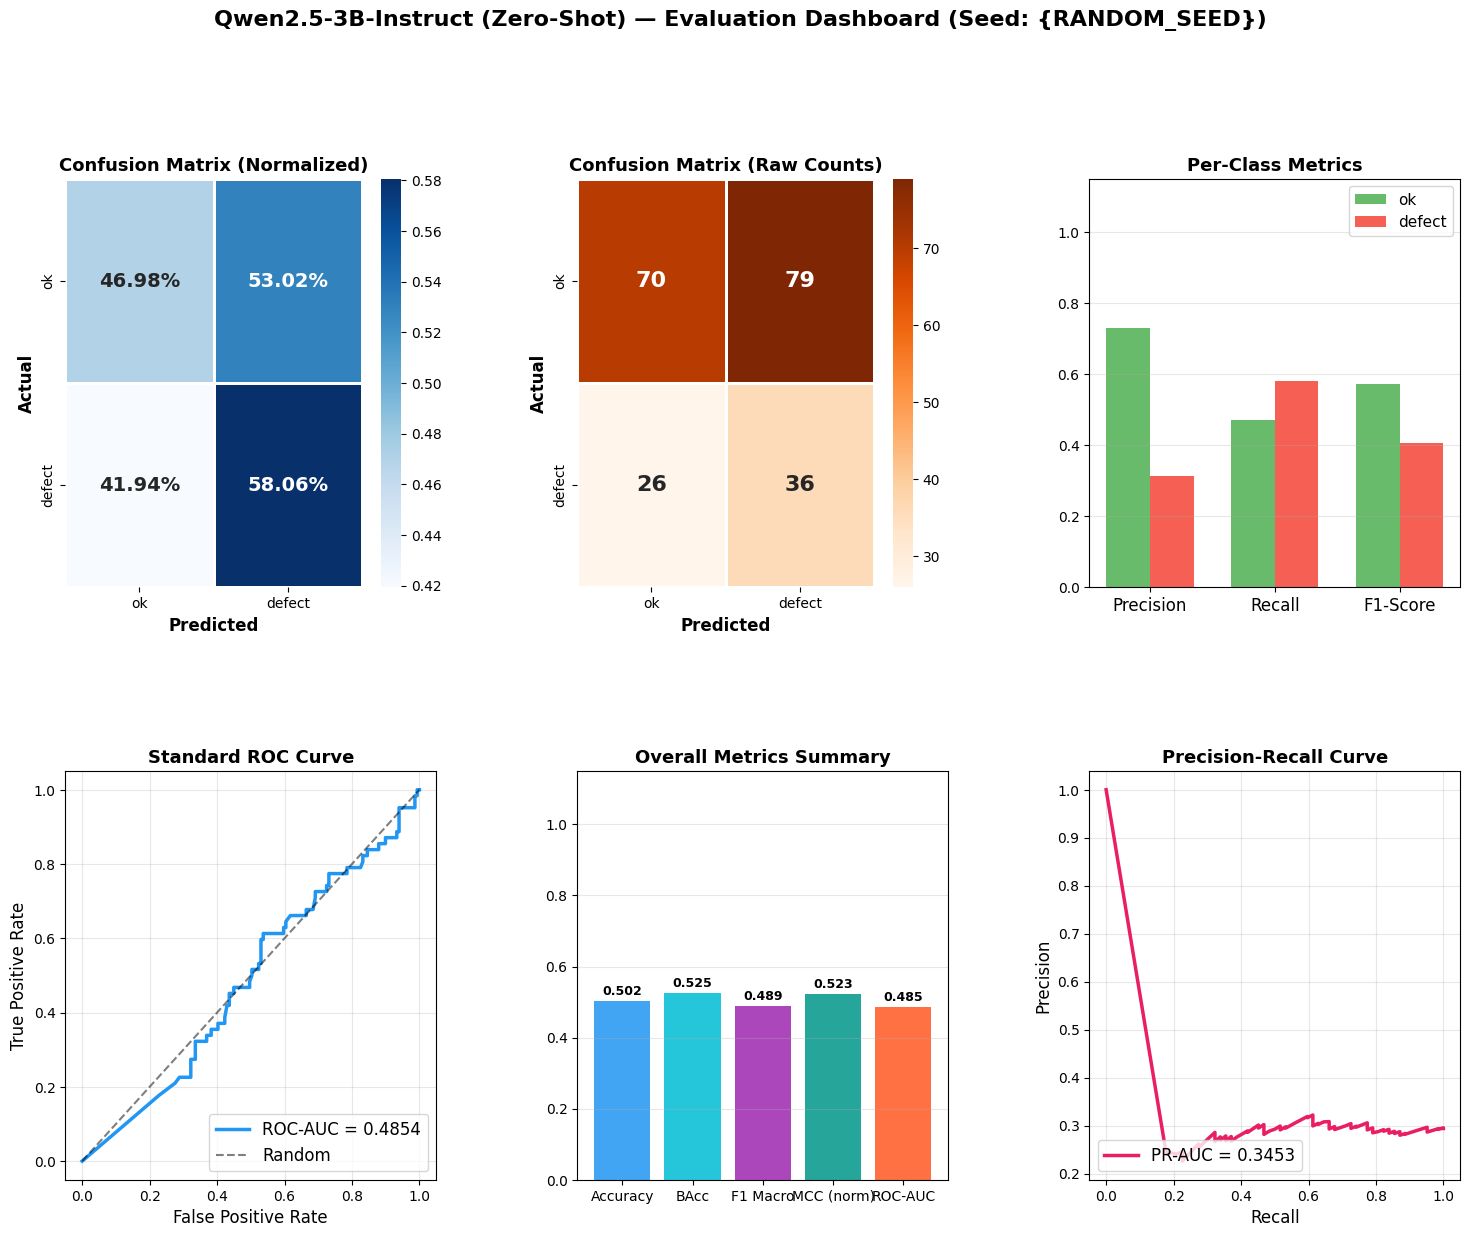

Dashboard saved: evaluation_dashboard_seed_123.png


In [13]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve, precision_recall_curve, auc as calc_auc, matthews_corrcoef
)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
import pandas as pd

label2int = {'ok': 0, 'defect': 1}
y_true_bin = [label2int[l] for l in y_true]
y_pred_bin = [label2int[l] for l in y_pred]
y_score    = y_scores

acc       = accuracy_score(y_true_bin, y_pred_bin)
bacc      = balanced_accuracy_score(y_true_bin, y_pred_bin)
prec_d    = precision_score(y_true_bin, y_pred_bin, pos_label=1)
rec_d     = recall_score(y_true_bin,    y_pred_bin, pos_label=1)
f1_d      = f1_score(y_true_bin,        y_pred_bin, pos_label=1)
prec_ok   = precision_score(y_true_bin, y_pred_bin, pos_label=0)
rec_ok    = recall_score(y_true_bin,    y_pred_bin, pos_label=0)
f1_ok     = f1_score(y_true_bin,        y_pred_bin, pos_label=0)
f1_macro  = f1_score(y_true_bin,        y_pred_bin, average='macro')
f1_weight = f1_score(y_true_bin,        y_pred_bin, average='weighted')
mcc       = matthews_corrcoef(y_true_bin, y_pred_bin)
cm        = confusion_matrix(y_true_bin, y_pred_bin)

try:
    roc_auc = roc_auc_score(y_true_bin, y_score)
    fpr, tpr, _ = roc_curve(y_true_bin, y_score)
except Exception as e:
    roc_auc = float('nan')

try:
    pr_prec, pr_rec, _ = precision_recall_curve(y_true_bin, y_score)
    pr_auc = calc_auc(pr_rec, pr_prec)
except Exception as e:
    pr_auc = float('nan')

print('=' * 58)
print('   EVALUATION REPORT — TEST SET (Seed: {RANDOM_SEED})')
print('=' * 58)
print(f'  Accuracy             : {acc:.4f}  ({acc*100:.2f}%)')
print(f'  Balanced Acc (BAcc)  : {bacc:.4f}')
print(f'  F1 (macro)           : {f1_macro:.4f}')
print(f'  F1 (weighted)        : {f1_weight:.4f}')
print(f'  MCC                  : {mcc:.4f}  (range: -1 ~ 1)')
print(f'  Standard ROC-AUC     : {roc_auc:.4f}')
print(f'  PR-AUC               : {pr_auc:.4f}')
print()
print('  Class: defect (Ambiguous)')
print(f'    Precision          : {prec_d:.4f}')
print(f'    Recall             : {rec_d:.4f}')
print(f'    F1-score           : {f1_d:.4f}')
print()
print('  Class: ok (Unambiguous)')
print(f'    Precision          : {prec_ok:.4f}')
print(f'    Recall             : {rec_ok:.4f}')
print(f'    F1-score           : {f1_ok:.4f}')
print('=' * 58)

fig = plt.figure(figsize=(18, 13))
gs  = gridspec.GridSpec(2, 3, hspace=0.45, wspace=0.38)

ax1 = fig.add_subplot(gs[0, 0])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=['ok','defect'], yticklabels=['ok','defect'],
            ax=ax1, linewidths=1, annot_kws={'size': 14, 'weight': 'bold'})
ax1.set_xlabel('Predicted', fontsize=12, fontweight='bold')
ax1.set_ylabel('Actual', fontsize=12, fontweight='bold')
ax1.set_title('Confusion Matrix (Normalized)', fontsize=13, fontweight='bold')

ax2 = fig.add_subplot(gs[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['ok','defect'], yticklabels=['ok','defect'],
            ax=ax2, linewidths=1, annot_kws={'size': 16, 'weight': 'bold'})
ax2.set_xlabel('Predicted', fontsize=12, fontweight='bold')
ax2.set_ylabel('Actual', fontsize=12, fontweight='bold')
ax2.set_title('Confusion Matrix (Raw Counts)', fontsize=13, fontweight='bold')

ax3 = fig.add_subplot(gs[0, 2])
metrics_names = ['Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics_names))
w = 0.35
ax3.bar(x - w/2, [prec_ok, rec_ok, f1_ok], w, label='ok', color='#4CAF50', alpha=0.85)
ax3.bar(x + w/2, [prec_d,  rec_d,  f1_d],  w, label='defect', color='#F44336', alpha=0.85)
ax3.set_xticks(x)
ax3.set_xticklabels(metrics_names, fontsize=12)
ax3.set_ylim(0, 1.15)
ax3.set_title('Per-Class Metrics', fontsize=13, fontweight='bold')
ax3.legend(fontsize=11)
ax3.grid(axis='y', alpha=0.3)

ax4 = fig.add_subplot(gs[1, 0])
if not np.isnan(roc_auc):
    ax4.plot(fpr, tpr, color='#2196F3', lw=2.5, label=f'ROC-AUC = {roc_auc:.4f}')
ax4.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5, label='Random')
ax4.set_xlabel('False Positive Rate', fontsize=12)
ax4.set_ylabel('True Positive Rate', fontsize=12)
ax4.set_title('Standard ROC Curve', fontsize=13, fontweight='bold')
ax4.legend(fontsize=12, loc='lower right')
ax4.grid(True, alpha=0.3)

ax5 = fig.add_subplot(gs[1, 1])
summary_names = ['Accuracy', 'BAcc', 'F1 Macro', 'MCC (norm)', 'ROC-AUC']
mcc_norm = (mcc + 1) / 2
summary_scores = [acc, bacc, f1_macro, mcc_norm, roc_auc if not np.isnan(roc_auc) else 0]
bars = ax5.bar(summary_names, summary_scores, color=['#2196F3','#00BCD4','#9C27B0','#009688','#FF5722'], alpha=0.85)
for bar, score in zip(bars, summary_scores):
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{score:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax5.set_ylim(0, 1.15)
ax5.set_title('Overall Metrics Summary', fontsize=13, fontweight='bold')
ax5.grid(axis='y', alpha=0.3)

ax6 = fig.add_subplot(gs[1, 2])
if not np.isnan(pr_auc):
    ax6.plot(pr_rec, pr_prec, color='#E91E63', lw=2.5, label=f'PR-AUC = {pr_auc:.4f}')
ax6.set_xlabel('Recall', fontsize=12)
ax6.set_ylabel('Precision', fontsize=12)
ax6.set_title('Precision-Recall Curve', fontsize=13, fontweight='bold')
ax6.legend(fontsize=12, loc='lower left')
ax6.grid(True, alpha=0.3)

fig.suptitle('Qwen2.5-3B-Instruct (Zero-Shot) — Evaluation Dashboard (Seed: {RANDOM_SEED})', fontsize=16, fontweight='bold', y=1.01)
plt.savefig(f'evaluation_dashboard_seed_{RANDOM_SEED}.png', dpi=130, bbox_inches='tight')
plt.show()
print(f'Dashboard saved: evaluation_dashboard_seed_{RANDOM_SEED}.png')


## 8. Failure Mode and Error Analysis
Identifies False Positive (Type I) and False Negative (Type II) misclassifications to analyze linguistic patterns and syntactic structures that induce zero-shot errors.

In [14]:
import textwrap

errors = df_test[~df_test['correct']].copy()
fn = errors[(errors['defect'] == 'defect') & (errors['predicted'] == 'ok')]
fp = errors[(errors['defect'] == 'ok')     & (errors['predicted'] == 'defect')]

print('=' * 60)
print('         ERROR ANALYSIS')
print('=' * 60)
print(f'Total errors    : {len(errors)} / {len(df_test)} ({len(errors)/len(df_test)*100:.1f}%)')
print(f'False Negatives : {len(fn)}  (missed defects (higher severity risk))')
print(f'False Positives : {len(fp)}  (false alarms (ok classified as defect))')

print('\n--- 5 False Negatives (ground-truth defect, predicted ok) ---')
for i, (_, row) in enumerate(fn.head(5).iterrows()):
    print(f'\n[FN {i+1}] {textwrap.fill(row["requirement"], 70)}')

print('\n--- 5 False Positives (ground-truth ok, predicted defect) ---')
for i, (_, row) in enumerate(fp.head(5).iterrows()):
    print(f'\n[FP {i+1}] {textwrap.fill(row["requirement"], 70)}')

errors[['requirement','defect','predicted']].to_csv('error_analysis.csv', index=False)
print('\nSaved errors to: error_analysis.csv')


         ERROR ANALYSIS
Total errors    : 105 / 211 (49.8%)
False Negatives : 26  (missed defects (higher severity risk))
False Positives : 79  (false alarms (ok classified as defect))

--- 5 False Negatives (ground-truth defect, predicted ok) ---

[FN 1] First extrapolations show that within the FoV of the near range scan
and the far range scan about 150 stationary objects can be detected,
tracked and/or predicted within a range of 100m in complex
environments on highways; taking into account the additional range
needed for obstacle classification the detection range and hence the
number of detectable objects will be even larger.

[FN 2] LIN-Master is the ECU that houses the PNM, the IBS works as LIN-Slave
with the possibility to wake up the Master-ECU in certain cases.

[FN 3] The start of the engine has also to be assured on hybrid systems that
might have much higher engine speed gradients while starting.

[FN 4] Changes in function blocks which have been transferred from earlier
pr

## 9. Artifact Serialization and Multi-Seed Results Export
Serializes hold-out test predictions and formal evaluation metrics into structured CSV and JSON files indexed by random seed to facilitate multi-seed statistical aggregation.

In [15]:
import json

metrics_data = {
    'model': 'llm_zero_shot',
    'seed': RANDOM_SEED,
    'accuracy': float(acc),
    'balanced_accuracy': float(bacc),
    'precision_defect': float(prec_d),
    'recall_defect': float(rec_d),
    'f1_defect': float(f1_d),
    'precision_ok': float(prec_ok),
    'recall_ok': float(rec_ok),
    'f1_ok': float(f1_ok),
    'f1_macro': float(f1_macro),
    'f1_weighted': float(f1_weight),
    'mcc': float(mcc),
    'roc_auc': float(roc_auc) if not np.isnan(roc_auc) else None,
    'pr_auc': float(pr_auc) if not np.isnan(pr_auc) else None,
    'confusion_matrix': cm.tolist(),
}

json_filename = f'metrics_llm_zero_shot_seed_{RANDOM_SEED}.json'
csv_filename  = f'predictions_llm_zero_shot_seed_{RANDOM_SEED}.csv'

with open(json_filename, 'w', encoding='utf-8') as f:
    json.dump(metrics_data, f, indent=2, ensure_ascii=False)

df_test.to_csv(csv_filename, index=False, encoding='utf-8')

print(f'Saved result files:')
print(f'   - Metrics JSON : {json_filename}')
print(f'   - Predictions  : {csv_filename}')


Saved result files:
   - Metrics JSON : metrics_llm_zero_shot_seed_123.json
   - Predictions  : predictions_llm_zero_shot_seed_123.csv


## 10. Qualitative Inference Routine
Provides an interactive verification routine for inspecting model predictions and posterior probability distributions on arbitrary SRS statements.

In [16]:
TEST_CASES = [
    "The system shall handle multiple sessions quickly and provide adequate performance.",
    "All data should be validated before it is stored.",
    "The system shall respond to all API requests within 200 milliseconds under normal load.",
    "The login module shall authenticate users using SHA-256 hashed passwords stored in PostgreSQL.",
]

print('Demo Inference (Local GPU)\n')
print('─' * 75)

for i, req in enumerate(TEST_CASES, 1):
    pred, prob = predict(req)
    icon = '' if pred == 'defect' else '✅'
    print(f'[{i}] {icon} {pred.upper()} (P(defect) = {prob*100:.1f}%)')
    print(f'     {req[:75]}...' if len(req) > 75 else f'     {req}')
    print()


Demo Inference (Local GPU)

───────────────────────────────────────────────────────────────────────────
[1] ✅ OK (P(defect) = 25.1%)
     The system shall handle multiple sessions quickly and provide adequate perf...

[2] ✅ OK (P(defect) = 0.0%)
     All data should be validated before it is stored.

[3] ✅ OK (P(defect) = 0.0%)
     The system shall respond to all API requests within 200 milliseconds under ...

[4] ✅ OK (P(defect) = 0.0%)
     The login module shall authenticate users using SHA-256 hashed passwords st...

